# 2D sliding-window clouds with Beta innovations

Compare the points $(X_t, X_{t+1})$ for different Beta shape parameters
$(a,b)$ while keeping the AR coefficients, sample size, and innovation
support width fixed. Run all cells, then edit **Settings** and rerun the
settings and plotting cells.

The process is $X_t=\sum_{j=1}^p\phi_jX_{t-j}+\varepsilon_t$, with
$\varepsilon_t=w\bigl(B_t-a/(a+b)\bigr)$ and $B_t\sim\operatorname{Beta}(a,b)$.
Innovations have mean zero and support width $w$. Their variance changes
with $(a,b)$; asymmetric choices also shift the support endpoints.
With $a=b=1$ and $w=2$, the innovations are uniform on $[-1,1]$.

Each panel overlays the theoretical support zonoid as a dashed red border.
Every figure is also saved as PDF and PNG.

In [4]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

AR_CODE_DIR = next(
    (
        candidate.resolve()
        for root in (Path.cwd(), *Path.cwd().parents)
        for candidate in (root / "Code" / "Code_AR_processes", root)
        if (candidate / "functions.py").is_file()
        and (candidate / "plotting_functions.py").is_file()
    ),
    None,
)
if AR_CODE_DIR is None:
    raise FileNotFoundError("Run this notebook from the project or AR code folder.")

PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Code.Code_AR_processes.functions import (
    ar_window_zonotope_generators,
    centered_beta_support,
    is_stationary,
    simulate_beta_ar,
    sliding_window_point_cloud,
    zonotope_polygon_2d,
)

NOTEBOOK_NAME = "ar_beta_sliding_window_2d"
PDF_DIR = AR_CODE_DIR / "outputs" / "pdfs" / NOTEBOOK_NAME
IMAGE_DIR = AR_CODE_DIR / "outputs" / "images" / NOTEBOOK_NAME
PDF_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

## Settings

Edit `beta_pairs` to choose the panels. For one cloud, use e.g.
`beta_pairs = [(2.0, 5.0)]`. Both shape parameters must be positive.
`phi = np.array([0.7])` gives an AR(1) process; use a longer stationary
coefficient vector for AR(2), AR(3), etc.

The seed is reset for each pair to make reruns reproducible. All panels
use identical axis limits and equal axis scales, with every point and the
whole zonoid shown. The border comes from the innovation support and AR
coefficients. AR(1) uses the exact infinite-history boundary; higher orders
use a finite-history approximation controlled by `zonoid_history` (increase
it for coefficients close to the stationarity boundary).

In [5]:
phi = np.array([0.7])
beta_pairs = [
    (1.0, 1.0),
    (0.5, 0.5),
    (2.0, 2.0),
    (5.0, 5.0),
    (2.0, 5.0),
    (5.0, 2.0),
]

sample_size = 5_000
burnin = 1_000
support_width = 2.0
process_seed = 42
columns = 3
point_size = 4
point_alpha = 0.35

# Only used for AR orders greater than one.
zonoid_history = 2_000


In [6]:
def theoretical_support_zonoid_2d(phi, innovation_bounds, history=2_000):
    """Support of the forward window (X_t, X_{t+1}), from the AR model.

    For innovation support [lower, upper], write each interval as its
    midpoint plus a symmetric segment. The support centre is the
    midpoint times sum(psi_j) = midpoint / (1 - sum(phi)) in both axes.
    The symmetric part is the Minkowski sum of the MA generator segments.
    """
    lower, upper = innovation_bounds
    half_width = 0.5 * (upper - lower)
    midpoint = 0.5 * (lower + upper)
    centre = np.full(2, midpoint / (1.0 - np.sum(phi)))

    if len(phi) == 1:
        # All past-innovation generators lie along (1, phi[0]).
        # Sum their absolute magnitudes exactly, including negative phi.
        coefficient = float(phi[0])
        generators = half_width * np.column_stack((
            np.array([1.0, coefficient]) / (1.0 - abs(coefficient)),
            np.array([0.0, 1.0]),
        ))
    else:
        if not isinstance(history, (int, np.integer)) or history < 1:
            raise ValueError("zonoid_history must be a positive integer.")
        # The shared generator routine is newest first; reverse its rows
        # to match the forward point clouds plotted here.
        generators = ar_window_zonotope_generators(
            phi, embedding_dimension=2, history=history,
            half_width=half_width,
        )[::-1]

    boundary = zonotope_polygon_2d(generators) + centre
    # Close the border explicitly to avoid tiny floating-point gaps.
    boundary[-1] = boundary[0]
    return boundary


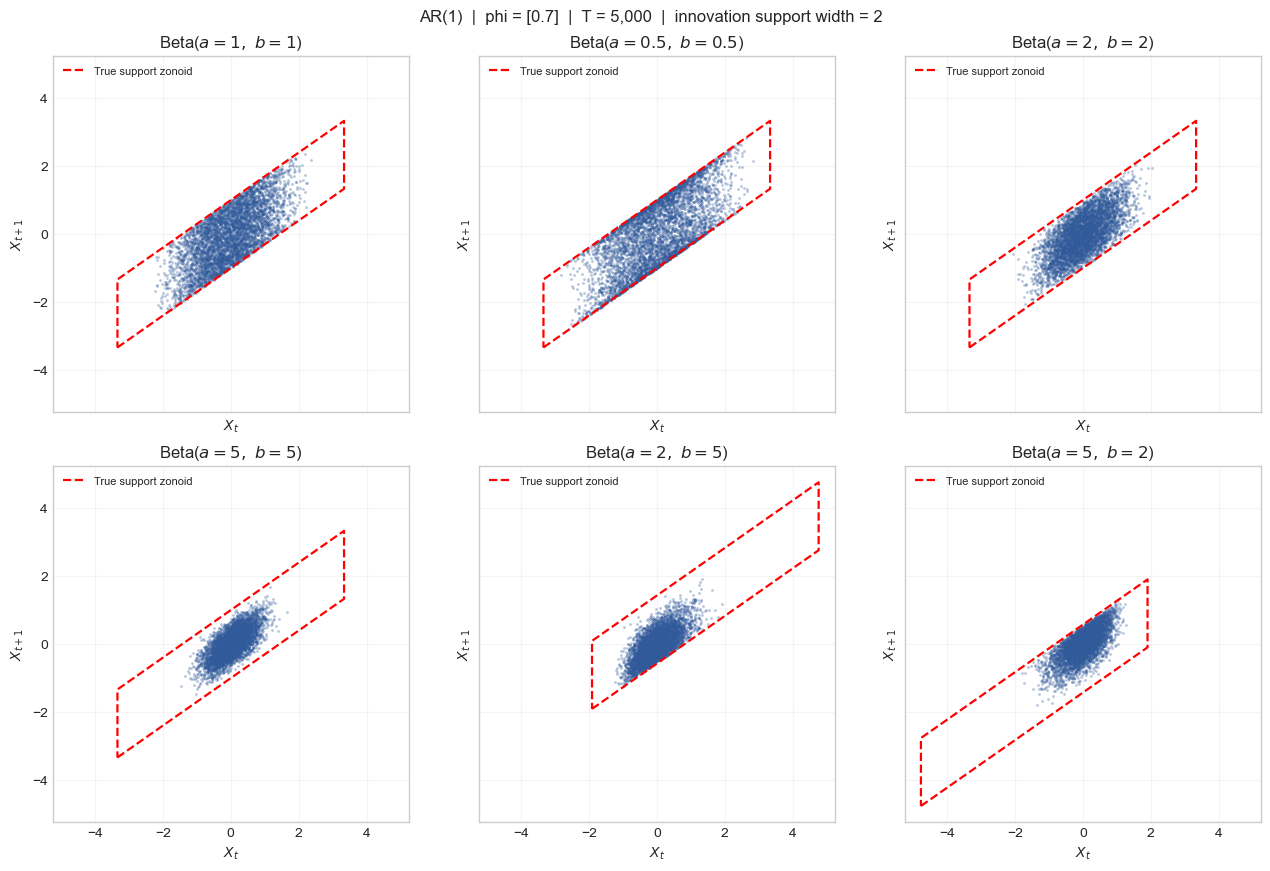

PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_beta_sliding_window_2d/beta_sliding_window_clouds_2d.pdf
PNG: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/images/ar_beta_sliding_window_2d/beta_sliding_window_clouds_2d.png


In [7]:
phi = np.asarray(phi, dtype=float)
if phi.ndim != 1 or len(phi) == 0 or not np.all(np.isfinite(phi)):
    raise ValueError("phi must be a nonempty, finite coefficient vector.")
stationary, _ = is_stationary(phi)
if not stationary:
    raise ValueError("Choose stationary AR coefficients (companion eigenvalues inside the unit circle).")
if not isinstance(sample_size, (int, np.integer)) or sample_size < 2:
    raise ValueError("sample_size must be an integer of at least 2.")
if not beta_pairs:
    raise ValueError("Add at least one (a, b) pair to beta_pairs.")
if not isinstance(columns, (int, np.integer)) or columns < 1:
    raise ValueError("columns must be a positive integer.")

clouds = []
zonoid_boundaries = []
for a, b in beta_pairs:
    innovation_bounds = centered_beta_support(
        alpha=a, beta=b, support_width=support_width
    )
    zonoid_boundaries.append(theoretical_support_zonoid_2d(
        phi, innovation_bounds, history=zonoid_history
    ))
    series = simulate_beta_ar(
        phi,
        sample_size=sample_size,
        burnin=burnin,
        support_width=support_width,
        alpha=a,
        beta=b,
        rng=process_seed,
    )
    cloud = sliding_window_point_cloud(
        series, embedding_dimension=2, newest_first=False
    )
    if not np.all(np.isfinite(cloud)):
        raise ValueError("The simulated cloud contains nonfinite values.")
    clouds.append(cloud)

all_shapes = clouds + zonoid_boundaries
lower = min(float(points.min()) for points in all_shapes)
upper = max(float(points.max()) for points in all_shapes)
margin = 0.05 * max(upper - lower, np.finfo(float).eps)
axis_limits = (lower - margin, upper + margin)
ncols = min(columns, len(beta_pairs))
nrows = (len(beta_pairs) + ncols - 1) // ncols

with plt.style.context("seaborn-v0_8-whitegrid"):
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(4.3 * ncols, 4.3 * nrows),
        sharex=True, sharey=True, squeeze=False,
        constrained_layout=True,
    )
    for ax, (a, b), cloud, boundary in zip(
        axes.flat, beta_pairs, clouds, zonoid_boundaries
    ):
        ax.scatter(
            cloud[:, 0], cloud[:, 1],
            s=point_size, alpha=point_alpha,
            color="#315a9a", linewidths=0, rasterized=True,
        )
        ax.plot(
            boundary[:, 0], boundary[:, 1],
            color="red", linestyle="--", linewidth=1.6, zorder=3,
            label="True support zonoid" if len(phi) == 1
            else f"Support zonoid (H={zonoid_history:,})",
        )
        ax.legend(loc="upper left", fontsize=8, framealpha=0.9)
        ax.set(
            title=fr"Beta($a={a:g},\ b={b:g}$)",
            xlabel=r"$X_t$", ylabel=r"$X_{t+1}$",
            xlim=axis_limits, ylim=axis_limits,
        )
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.2)
    for ax in list(axes.flat)[len(beta_pairs):]:
        ax.set_visible(False)

    coefficient_label = np.array2string(phi, precision=3, separator=", ")
    fig.suptitle(
        f"AR({len(phi)})  |  phi = {coefficient_label}  |  "
        f"T = {sample_size:,}  |  innovation support width = {support_width:g}",
        fontsize=12,
    )
    pdf_path = PDF_DIR / "beta_sliding_window_clouds_2d.pdf"
    image_path = IMAGE_DIR / "beta_sliding_window_clouds_2d.png"
    fig.savefig(pdf_path, bbox_inches="tight")
    fig.savefig(image_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print(f"PDF: {pdf_path}")
print(f"PNG: {image_path}")